# 06 - Engagement segmentation

**Question:** Which groups of users show low or declining observed activity, so a product team knows where to look?

**Wording matters.** Three months of data cannot show that anyone has *churned*. This notebook uses:
- **inactive in the observed window**: no events in the last 30 days of the sample;
- **declining activity indicator**: active in the previous 30 days, silent in the last 30.

There is no prediction model here on purpose. A churn classifier needs a future outcome label, a time-based train/test split and leakage checks. With one short window, a transparent rule-based segment is the defensible choice.

In [1]:
# --- Setup: run this cell first ---
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "productpulse").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from productpulse import data, metrics, charts

charts.apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print(data.data_banner())

Real BigQuery export loaded from: C:\Users\Padmashree\OneDrive\Desktop\ProductPulse-AI\ProductPulse-AI\data\exports


## 1. Build transparent features (one row per user)

In [2]:
fact, dim = data.load_model()
ANALYSIS_DATE = fact["event_dt"].max()          # stated explicitly: every recency feature depends on it
feats = metrics.engagement_features(fact, dim, ANALYSIS_DATE)
print("Analysis date:", ANALYSIS_DATE.date())
print("Users:", f"{len(feats):,}")

feature_notes = pd.DataFrame([
    ("active_days", "Distinct dates with any event, whole sample", "Late arrivals have fewer possible days"),
    ("sessions", "Sum of daily distinct session ids", "A session crossing midnight counts on both days"),
    ("days_since_last_event", "Analysis date minus last active date", "Depends on the analysis date"),
    ("active_days_30d", "Distinct active dates in the last 30 days", "Users first seen recently are always 'active'"),
    ("active_days_prior_30d", "Distinct active dates in the 30 days before that", "Not defined for users first seen later"),
    ("purchase_count", "Validated orders (distinct transaction ids)", "Purchase events without an id are excluded"),
    ("observed_days", "Days from first seen to the analysis date", "Exposure: use it to compare like with like"),
], columns=["feature", "definition", "caution"])
display(feature_notes)
display(feats[["active_days", "sessions", "events", "engagement_min", "days_since_last_event",
               "active_days_30d", "purchase_count", "observed_days"]].describe(percentiles=[0.5, 0.9, 0.99]).T
        .style.format("{:,.2f}"))

Analysis date: 2021-01-31
Users: 270,154


,feature,definition,caution
0,active_days,"Distinct dates with any event, whole sample",Late arrivals have fewer possible days
1,sessions,Sum of daily distinct session ids,A session crossing midnight counts on both days
2,days_since_last_event,Analysis date minus last active date,Depends on the analysis date
3,active_days_30d,Distinct active dates in the last 30 days,Users first seen recently are always 'active'
4,active_days_prior_30d,Distinct active dates in the 30 days before that,Not defined for users first seen later
5,purchase_count,Validated orders (distinct transaction ids),Purchase events without an id are excluded
6,observed_days,Days from first seen to the analysis date,Exposure: use it to compare like with like


,count,mean,std,min,50%,90%,99%,max
active_days,"270,154.00",1.18,0.66,1.00,1.00,2.00,4.00,12.00
sessions,"270,154.00",1.34,1.01,1.00,1.00,2.00,6.00,13.00
events,"270,154.00",15.90,39.03,1.00,6.00,28.00,220.47,"1,309.00"
engagement_min,"270,154.00",1.56,6.60,0.00,0.17,3.29,24.17,"1,179.98"
days_since_last_event,"270,154.00",43.81,25.64,0.00,45.00,80.00,90.00,91.00
active_days_30d,"270,154.00",0.39,0.60,0.00,0.00,1.00,2.00,11.00
purchase_count,"270,154.00",0.02,0.17,0.00,0.00,0.00,1.00,16.00
observed_days,"270,154.00",46.05,25.82,1.00,47.00,82.00,91.00,92.00


## 2. Rule-based segments

| Segment | Rule (first match wins) |
|---|---|
| **1 High** | active on 3 or more days, **or** made a purchase |
| **2 Medium** | active on exactly 2 days, **or** viewed an item / added to cart |
| **3 Low** | everyone else: one day, no product interaction |

These thresholds are analytical choices, not ground truth. The same rules are implemented in SQL (`sql/07_segment_analysis.sql`, Q34) so the dashboard can show them.

,users,avg_active_days,median_events,median_engagement_min,share_viewed_item,share_purchased,revenue_usd,avg_days_since_last_event,share_of_users,share_of_revenue
engagement_segment,,,,,,,,,,
1 High,"12,348",3.43,70,7.5,75.4%,35.8%,"308,200",40.2,4.6%,100.0%
2 Medium,"63,130",1.30,14,1.1,82.3%,0.0%,0,45.5,23.4%,0.0%
3 Low,"194,676",1.00,5,0.1,0.0%,0.0%,0,43.5,72.1%,0.0%


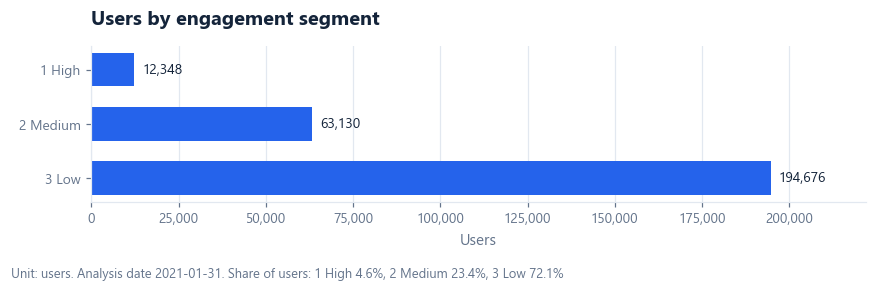

1 High: 4.6% of users, 100.0% of revenue
2 Medium: 23.4% of users, 0.0% of revenue
3 Low: 72.1% of users, 0.0% of revenue


In [3]:
profile = feats.groupby("engagement_segment").agg(
    users=("user_pseudo_id", "size"),
    avg_active_days=("active_days", "mean"),
    median_events=("events", "median"),
    median_engagement_min=("engagement_min", "median"),
    share_viewed_item=("viewed_item", "mean"),
    share_purchased=("purchased", "mean"),
    revenue_usd=("revenue_usd", "sum"),
    avg_days_since_last_event=("days_since_last_event", "mean"),
)
profile["share_of_users"] = profile["users"] / profile["users"].sum()
profile["share_of_revenue"] = profile["revenue_usd"] / profile["revenue_usd"].sum()
display(profile.style.format({"users": "{:,.0f}", "avg_active_days": "{:.2f}", "median_events": "{:,.0f}",
                              "median_engagement_min": "{:.1f}", "share_viewed_item": "{:.1%}",
                              "share_purchased": "{:.1%}", "revenue_usd": "{:,.0f}",
                              "avg_days_since_last_event": "{:.1f}", "share_of_users": "{:.1%}",
                              "share_of_revenue": "{:.1%}"}))

fig, ax = charts.bar_chart(profile.index, profile["users"], "Users by engagement segment", "Users")
charts.note(fig, f"Unit: users. Analysis date {ANALYSIS_DATE.date()}. Share of users: "
                 + ", ".join(f"{k} {v:.1%}" for k, v in profile["share_of_users"].items()))
charts.save_figure(fig, "06_segments")
plt.show()

for seg, row in profile.iterrows():
    print(f"{seg}: {row['share_of_users']:.1%} of users, {row['share_of_revenue']:.1%} of revenue")

**Interpretation (write this yourself after running on the real export)**

- *Observation:* each segment's share of users and of revenue.
- *Possible explanation (unproven):* a small engaged group usually carries most revenue; the Low segment may be mostly one-off referral visits.
- *Next check:* check whether the Low segment's share differs by channel (section 3) before suggesting any action.

## 3. Where do the segments come from?

engagement_segment,1 High,2 Medium,3 Low,users
device_category,,,,
desktop,4.5%,23.5%,72.0%,"156,905"
mobile,4.7%,23.2%,72.2%,"107,175"
tablet,4.0%,24.6%,71.4%,"6,074"


engagement_segment,1 High,2 Medium,3 Low,users
channel_group,,,,
Organic search,4.3%,23.2%,72.5%,"101,742"
Direct,4.5%,23.3%,72.2%,"64,109"
Other,3.9%,22.9%,73.2%,"47,101"
Referral,5.2%,23.7%,71.1%,"40,019"
Paid search,4.3%,22.8%,72.9%,"14,282"
Data deleted,19.5%,34.9%,45.5%,"2,901"


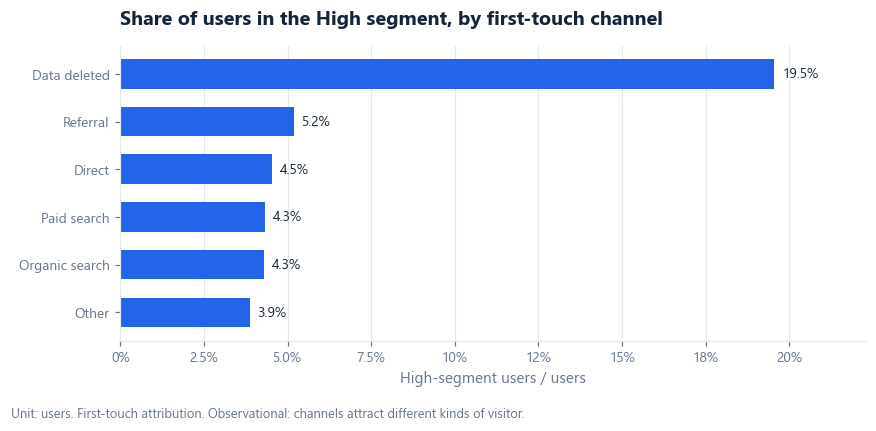

In [4]:
for column in ["device_category", "channel_group"]:
    mix = pd.crosstab(feats[column], feats["engagement_segment"], normalize="index")
    mix["users"] = feats[column].value_counts()
    mix = mix.sort_values("users", ascending=False)
    display(mix.style.format({c: "{:.1%}" for c in mix.columns if c != "users"} | {"users": "{:,.0f}"}))

by_channel = (feats.groupby("channel_group").agg(users=("user_pseudo_id", "size"),
              high=("engagement_segment", lambda s: (s == "1 High").sum())).reset_index())
by_channel["share_high"] = by_channel["high"] / by_channel["users"]
by_channel = by_channel.sort_values("share_high", ascending=False)
fig, ax = charts.bar_chart(by_channel["channel_group"], by_channel["share_high"],
                           "Share of users in the High segment, by first-touch channel", "High-segment users / users", percent=True)
charts.note(fig, "Unit: users. First-touch attribution. Observational: channels attract different kinds of visitor.")
charts.save_figure(fig, "06_high_share_by_channel")
plt.show()

## 4. Inactive in the observed window, and the declining-activity indicator

Only users who have been observable long enough are included:
- *Inactive 30+ days* is reported for users first seen **more than 30 days** before the analysis date.
- *Declining activity* is reported for users first seen **before the last 30 days began** (so they had a prior window to be active in).

Mature users in the Low segment are inactive by construction (one active day, more than 30 days ago), so the informative rows are High and Medium.

In [5]:
mature = feats[feats["observed_days"] > 30]
inactive = (mature["days_since_last_event"] >= 30)
print(f"Users first seen more than 30 days before {ANALYSIS_DATE.date()}: {len(mature):,}")
print(f"Inactive for 30+ days in the observed window: {inactive.sum():,} ({inactive.mean():.1%})")

by_seg = mature.assign(inactive_30d=inactive).groupby("engagement_segment").agg(
    users=("inactive_30d", "size"), inactive_30d=("inactive_30d", "sum"))
by_seg["share_inactive_30d"] = by_seg["inactive_30d"] / by_seg["users"]
display(by_seg.style.format({"users": "{:,.0f}", "inactive_30d": "{:,.0f}", "share_inactive_30d": "{:.1%}"}))

decl = feats.dropna(subset=["declining_activity"])
prior_active = decl[decl["active_days_prior_30d"] > 0]
went_quiet = int(prior_active["declining_activity"].sum())
print(f"\nUsers active in the prior 30-day window: {len(prior_active):,}")
print(f"Of those, silent in the last 30 days (declining-activity indicator): {went_quiet:,} "
      f"({metrics.safe_div(went_quiet, len(prior_active)):.1%})")

quiet_buyers = prior_active[(prior_active["declining_activity"] == 1) & (prior_active["purchased"] == 1)]
print(f"Past purchasers among them: {len(quiet_buyers):,} users, ${quiet_buyers['revenue_usd'].sum():,.0f} of observed revenue")

by_dev = prior_active.groupby("device_category").agg(users=("declining_activity", "size"),
                                                     went_quiet=("declining_activity", "sum"))
by_dev["share_went_quiet"] = by_dev["went_quiet"] / by_dev["users"]
display(by_dev.style.format({"users": "{:,.0f}", "went_quiet": "{:,.0f}", "share_went_quiet": "{:.1%}"}))

Users first seen more than 30 days before 2021-01-31: 181,033
Inactive for 30+ days in the observed window: 177,329 (98.0%)


,users,inactive_30d,share_inactive_30d
engagement_segment,,,
1 High,"10,058","7,760",77.2%
2 Medium,"43,964","42,558",96.8%
3 Low,"127,011","127,011",100.0%



Users active in the prior 30-day window: 99,543
Of those, silent in the last 30 days (declining-activity indicator): 96,432 (96.9%)
Past purchasers among them: 1,827 users, $150,398 of observed revenue


,users,went_quiet,share_went_quiet
device_category,,,
desktop,"57,948","56,149",96.9%
mobile,"39,365","38,115",96.8%
tablet,"2,230","2,168",97.2%


**Interpretation (write this yourself after running on the real export)**

- *Observation:* the share of mature users inactive for 30+ days, and how many past purchasers went quiet.
- *Possible explanation (unproven):* a merchandise store has a naturally long gap between visits; seasonal December shoppers may not return in January.
- *Next check:* with a longer dataset, define a proper outcome (no activity in the *next* 60 days) and test whether these features predict it.

## 5. Caveats to state whenever these segments are shown

1. **Not churn.** "Inactive in the observed window" only. Many of these users may return in February.
2. **Seasonality.** The last 30 days are January and the prior window is December, a holiday month. Lower January activity is expected for any retailer.
3. **Identity.** `user_pseudo_id` is a browser/device id. Cleared cookies or a new phone looks like a user who went quiet.
4. **Exposure.** A user first seen on 25 January cannot have 3 active days yet. Compare segments within similar `observed_days`, as section 4 does.
5. **Thresholds are choices.** Changing "3 or more days" to "2 or more" moves users between segments. Report the rule with the result.
6. **No causality.** A channel with more High users did not *make* them engaged.